# Geo-Indistinguishability: Restaurant Inspection Data
**Single-query and multi-record Bayesian linkage attacks on NYC DOHMH inspections + PLUTO**

Workflow:
1. Load & clean data (inspections train/test, PLUTO)
2. Learn Bayesian priors from training data
3. Single-query attack (ablation study)
4. Multi-record attack (composition evaluation)
5. Utility evaluation
6. Density stratification
7. Posterior analysis
8. Visualization

In [2]:
import pandas as pd
import geopandas as gpd
import numpy as np
import requests, json
from io import StringIO
from scipy.special import lambertw
from scipy.spatial import KDTree
from scipy.optimize import brentq
from scipy.stats import gaussian_kde, spearmanr
from shapely.geometry import Point
from pyproj import Transformer
from collections import defaultdict
import matplotlib.pyplot as plt

## 0. Helper functions

In [3]:
# ── Mechanism ──

def planar_laplace(x, y, epsilon):
    n = len(x)
    theta = np.random.uniform(0, 2 * np.pi, size=n)
    p = np.random.uniform(0, 1, size=n)
    r = -(lambertw(-(1 - p) / np.e, k=-1).real + 1) / epsilon
    return x + r * np.cos(theta), y + r * np.sin(theta)


# ── Prior construction ──

def build_prior_table(df, col_insp, col_pluto):
    ct = df.groupby([col_insp, col_pluto]).size().unstack(fill_value=0)
    return ct.div(ct.sum(axis=1), axis=0)


def build_lookup(prior_table, ref_df, pluto_col, smoothing=0.01):
    lookup = {}
    for val in prior_table.index:
        row = prior_table.loc[val]
        weights = ref_df[pluto_col].map(row).fillna(smoothing).values.astype(float)
        lookup[val] = np.maximum(weights, smoothing)
    return lookup


# ── Search radius from mechanism CDF ──

def get_search_radius(epsilon, target=0.99):
    return brentq(lambda r: 1 - (1 + epsilon*r)*np.exp(-epsilon*r) - target,
                  0, 10 / epsilon)


# ── Attack engine ──

def run_attack(test_df, noisy_coords, ref_df, ref_coords, tree,
               epsilon, config, prior_lookups):
    ref_bbls = ref_df['bbl'].values
    uniform  = np.ones(len(ref_df))
    n = len(test_df)
    guessed_bbls = np.empty(n, dtype=int)

    if not config:
        _, indices = tree.query(noisy_coords, k=1)
        return ref_bbls[indices]

    search_radius = get_search_radius(epsilon, target=0.99)

    test_attrs = {}
    for prior_key, col_insp in config:
        test_attrs[(prior_key, col_insp)] = test_df[col_insp].values

    for i in range(n):
        idxs = tree.query_ball_point(noisy_coords[i], r=search_radius)

        if len(idxs) == 0:
            _, idx = tree.query(noisy_coords[i], k=1)
            guessed_bbls[i] = ref_bbls[idx]
            continue

        idxs = np.array(idxs)
        dists = np.linalg.norm(ref_coords[idxs] - noisy_coords[i], axis=1)

        weights = np.ones(len(idxs))
        for prior_key, col_insp in config:
            val = test_attrs[(prior_key, col_insp)][i]
            if pd.isna(val):
                continue
            full_weights = prior_lookups[prior_key].get(val, uniform)
            weights *= full_weights[idxs]

        log_prior  = np.log(np.maximum(weights, 1e-10))
        log_scores = log_prior - epsilon * dists
        guessed_bbls[i] = ref_bbls[idxs[np.argmax(log_scores)]]

        if i % 5000 == 0:
            print(f'  {i}/{n}')

    return guessed_bbls

## 1. Load & clean data

In [ ]:
# ── PLUTO ──

PLUTO_PATH = #replace with correct path

ref_df = pd.read_csv(
    PLUTO_PATH,
    usecols=['BBL', 'xcoord', 'ycoord', 'landuse', 'bldgclass',
             'unitsres', 'unitstotal', 'numfloors', 'yearbuilt',
             'bldgarea', 'borough']
)
ref_df = ref_df.rename(columns={'BBL': 'bbl'})
ref_df = ref_df.dropna(subset=['bbl', 'xcoord', 'ycoord'])
ref_df['bbl'] = ref_df['bbl'].astype(int)
ref_df['landuse'] = ref_df['landuse'].fillna('unknown').astype(str)
ref_df['borough'] = ref_df['borough'].fillna('unknown').astype(str)

# bin continuous columns
ref_df['units_bin'] = pd.cut(ref_df['unitsres'].fillna(0),
    bins=[-1, 0, 1, 5, 20, 100, 10000],
    labels=['0','1','2-5','6-20','21-100','100+']).astype(str)
ref_df['year_bin'] = pd.cut(ref_df['yearbuilt'].fillna(0),
    bins=[-1, 1920, 1950, 1980, 2000, 2030],
    labels=['pre-1920','1920-50','1950-80','1980-2000','post-2000']).astype(str)

print(f'PLUTO rows: {len(ref_df)}')

PLUTO rows: 857103


In [11]:
# ── Inspection data — training (2020-2025), test (2025-2026) ──

API = 'https://data.cityofnewyork.us/resource/43nn-pn8j.csv'
COLS = 'camis,inspection_date,latitude,longitude,bbl,boro,cuisine_description,critical_flag,score,grade'

def fetch_inspections(where_clause, label):
    all_pages = []
    offset = 0
    while True:
        r = requests.get(API, params={
            '$where': where_clause, '$limit': 50000,
            '$offset': offset, '$select': COLS
        })
        chunk = pd.read_csv(StringIO(r.text))
        if len(chunk) == 0:
            break
        all_pages.append(chunk)
        offset += 50000
        print(f'  {label}: fetched {offset} rows...')
    raw = pd.concat(all_pages, ignore_index=True)
    visits = raw.drop_duplicates(subset=['camis', 'inspection_date'])
    visits = visits.dropna(subset=['latitude', 'longitude', 'bbl']).copy()
    visits['bbl'] = visits['bbl'].astype(int)
    print(f'{label}: {len(visits)} visits, {visits["camis"].nunique()} restaurants')
    return visits

train_visits = fetch_inspections("inspection_date between '2020-01-01' and '2025-01-01'", 'Training')
test = fetch_inspections("inspection_date >= '2025-01-01'", 'Test')

# only keep test records whose BBL exists in PLUTO
test = test[test['bbl'].isin(ref_df['bbl'].values)].copy()

multi_counts = test.groupby('camis').size()

print(f'\nTraining: {len(train_visits)} visits, {train_visits["camis"].nunique()} restaurants')
print(f'Test: {len(test)} visits, {test["camis"].nunique()} restaurants')
print(f'Restaurants with 2+ inspections: {(multi_counts >= 2).sum()}')
print(f'Restaurants with 3+ inspections: {(multi_counts >= 3).sum()}')
print(f'\nDistribution of inspections per restaurant:')
print(multi_counts.value_counts().sort_index().head(10))

  Training: fetched 50000 rows...
  Training: fetched 100000 rows...
  Training: fetched 150000 rows...
  Training: fetched 200000 rows...
Training: 44321 visits, 21637 restaurants
  Test: fetched 50000 rows...
  Test: fetched 100000 rows...
  Test: fetched 150000 rows...
Test: 38762 visits, 25264 restaurants

Training: 44321 visits, 21637 restaurants
Test: 37860 visits, 24595 restaurants
Restaurants with 2+ inspections: 8983
Restaurants with 3+ inspections: 2732

Distribution of inspections per restaurant:
1     15612
2      6251
3      1756
4       628
5       207
6        88
7        31
8        14
9         7
11        1
Name: count, dtype: int64


In [12]:
# ── Project lat/lon to State Plane (EPSG:2263, feet) ──

transformer = Transformer.from_crs('EPSG:4326', 'EPSG:2263', always_xy=True)

for df in [train_visits, test]:
    x, y = transformer.transform(df['longitude'].values, df['latitude'].values)
    df['x'] = x
    df['y'] = y

print('Projection done.')
print(test[['longitude', 'latitude', 'x', 'y']].head())

Projection done.
   longitude   latitude             x              y
0 -73.976258  40.681976  9.908350e+05  187739.658344
1 -73.820317  40.824587  1.033979e+06  239747.794092
2 -73.897827  40.708154  1.012577e+06  197292.689852
3 -73.831748  40.708463  1.030897e+06  197433.596669
4 -73.977050  40.747208  9.906090e+05  211505.775411


## 2. Learn priors from training data

In [13]:
# ── Merge training inspections → PLUTO via BBL ──

train_merged = train_visits.merge(
    ref_df[['bbl', 'landuse', 'bldgclass', 'unitsres', 'numfloors',
            'yearbuilt', 'bldgarea', 'borough']],
    on='bbl', how='inner'
)

train_merged['units_bin'] = pd.cut(train_merged['unitsres'].fillna(0),
    bins=[-1, 0, 1, 5, 20, 100, 10000],
    labels=['0','1','2-5','6-20','21-100','100+']).astype(str)
train_merged['year_bin'] = pd.cut(train_merged['yearbuilt'].fillna(0),
    bins=[-1, 1920, 1950, 1980, 2000, 2030],
    labels=['pre-1920','1920-50','1950-80','1980-2000','post-2000']).astype(str)

print(f'Joined: {len(train_merged)} / {len(train_visits)}')

Joined: 43237 / 44321


In [14]:
# ── Build prior tables and fast lookups ──

prior_tables = {
    'boro__borough':                 build_prior_table(train_merged, 'boro', 'borough'),
    'cuisine_description__landuse':  build_prior_table(train_merged, 'cuisine_description', 'landuse'),
    'cuisine_description__units_bin': build_prior_table(train_merged, 'cuisine_description', 'units_bin'),
    'cuisine_description__year_bin': build_prior_table(train_merged, 'cuisine_description', 'year_bin'),
}

prior_lookups = {
    'boro__borough':                 build_lookup(prior_tables['boro__borough'], ref_df, 'borough'),
    'cuisine_description__landuse':  build_lookup(prior_tables['cuisine_description__landuse'], ref_df, 'landuse'),
    'cuisine_description__units_bin': build_lookup(prior_tables['cuisine_description__units_bin'], ref_df, 'units_bin'),
    'cuisine_description__year_bin': build_lookup(prior_tables['cuisine_description__year_bin'], ref_df, 'year_bin'),
}

for key, lk in prior_lookups.items():
    w = lk[next(iter(lk))]
    print(f'{key}: {len(lk)} values, min={w.min():.4f}, max={w.max():.4f}')

boro__borough: 5 values, min=0.0100, max=1.0000
cuisine_description__landuse: 89 values, min=0.0100, max=0.6500
cuisine_description__units_bin: 89 values, min=0.0100, max=0.5000
cuisine_description__year_bin: 89 values, min=0.0100, max=0.7000


In [15]:
# ── Ablation configurations ──

configs = {
    'spatial_only':     [],
    'borough_only':     [('boro__borough', 'boro')],
    'cuisine_landuse':  [('cuisine_description__landuse', 'cuisine_description')],
    'cuisine_units':    [('cuisine_description__units_bin', 'cuisine_description')],
    'cuisine_year':     [('cuisine_description__year_bin', 'cuisine_description')],
}

epsilon_vals = [0.001, 0.002, 0.005, 0.01, 0.02, 0.05]

print('Search radii at 99% coverage:')
for eps in epsilon_vals:
    r = get_search_radius(eps)
    print(f'  eps={eps}: {r:.0f} feet ({r/5280:.2f} miles)')

Search radii at 99% coverage:
  eps=0.001: 6638 feet (1.26 miles)
  eps=0.002: 3319 feet (0.63 miles)
  eps=0.005: 1328 feet (0.25 miles)
  eps=0.01: 664 feet (0.13 miles)
  eps=0.02: 332 feet (0.06 miles)
  eps=0.05: 133 feet (0.03 miles)


## 3. Single-query attack (ablation)

In [16]:
np.random.seed(42)

ref_coords  = ref_df[['xcoord', 'ycoord']].values
tree        = KDTree(ref_coords)
actual_bbls = test['bbl'].values

results = []
all_guesses = {}

for epsilon in epsilon_vals:
    noisy_x, noisy_y = planar_laplace(test['x'].values, test['y'].values, epsilon)
    noisy_coords = np.column_stack([noisy_x, noisy_y])

    for config_name, config in configs.items():
        print(f'\n{config_name} | eps={epsilon}')
        guessed_bbls = run_attack(
            test, noisy_coords, ref_df, ref_coords, tree,
            epsilon, config, prior_lookups
        )
        rate = np.mean(guessed_bbls == actual_bbls)
        results.append({'config': config_name, 'epsilon': epsilon, 'reid_rate': rate})
        all_guesses[(epsilon, config_name)] = guessed_bbls
        print(f'  reidentification = {rate:.4f}')

    # checkpoint
    pd.DataFrame(results).to_csv('results_restaurant_checkpoint.csv', index=False)

results_df = pd.DataFrame(results)
print('\n=== SINGLE-QUERY RESULTS ===')
print(results_df.pivot(index='epsilon', columns='config', values='reid_rate').round(4))


spatial_only | eps=0.001
  reidentification = 0.0048

borough_only | eps=0.001
  0/37860
  5000/37860
  10000/37860
  15000/37860
  20000/37860
  25000/37860
  30000/37860
  35000/37860
  reidentification = 0.0048

cuisine_landuse | eps=0.001
  0/37860
  5000/37860
  10000/37860
  15000/37860
  20000/37860
  25000/37860
  30000/37860
  35000/37860
  reidentification = 0.0082

cuisine_units | eps=0.001
  0/37860
  5000/37860
  10000/37860
  15000/37860
  20000/37860
  25000/37860
  30000/37860
  35000/37860
  reidentification = 0.0049

cuisine_year | eps=0.001
  0/37860
  5000/37860
  10000/37860
  15000/37860
  20000/37860
  25000/37860
  30000/37860
  35000/37860
  reidentification = 0.0031

spatial_only | eps=0.002
  reidentification = 0.0113

borough_only | eps=0.002
  0/37860
  5000/37860
  10000/37860
  15000/37860
  20000/37860
  25000/37860
  30000/37860
  35000/37860
  reidentification = 0.0113

cuisine_landuse | eps=0.002
  0/37860
  5000/37860
  10000/37860
  15000/37860
  2

## 4. Multi-record attack (composition evaluation)

In [17]:
# ── Multi-record attack: intersect candidates, score jointly ──
# The attacker sees n independent noisy locations for the same restaurant.
# Instead of averaging, they:
#   1. Find candidates within radius of each noisy observation
#   2. Intersect the candidate sets
#   3. Score jointly: log_score(x) = log_prior(x) - eps * sum(d(x, z_i))
# This directly tests Section 3.3: n observations degrade privacy to n*eps.

np.random.seed(42)

def multi_record_attack(camis_group, ref_df, ref_coords, tree, epsilon,
                         config, prior_lookups):
    """Attack a single restaurant using n noisy observations."""
    ref_bbls = ref_df['bbl'].values
    uniform = np.ones(len(ref_df))
    search_radius = get_search_radius(epsilon, target=0.99)
    
    noisy_points = camis_group[['nx', 'ny']].values  # (n_obs, 2)
    n_obs = len(noisy_points)
    
    # step 1-2: find candidates for each observation
    candidate_sets = []
    for j in range(n_obs):
        idxs = tree.query_ball_point(noisy_points[j], r=search_radius)
        candidate_sets.append(set(idxs))
    
    # step 3: intersect candidate sets
    candidates = candidate_sets[0]
    for s in candidate_sets[1:]:
        candidates = candidates.intersection(s)
    
    # fall back to union if intersection is empty
    if len(candidates) == 0:
        candidates = candidate_sets[0]
        for s in candidate_sets[1:]:
            candidates = candidates.union(s)
    
    if len(candidates) == 0:
        # absolute fallback: nearest neighbor to first noisy point
        _, idx = tree.query(noisy_points[0], k=1)
        return ref_bbls[idx]
    
    idxs = np.array(list(candidates))
    
    # step 4: joint scoring
    # log_likelihood = -eps * sum of distances to all noisy points
    total_dist = np.zeros(len(idxs))
    for j in range(n_obs):
        total_dist += np.linalg.norm(ref_coords[idxs] - noisy_points[j], axis=1)
    
    # prior
    weights = np.ones(len(idxs))
    if config:
        for prior_key, col_insp in config:
            val = camis_group[col_insp].iloc[0]  # same restaurant, same attribute
            if pd.isna(val):
                continue
            full_weights = prior_lookups[prior_key].get(val, uniform)
            weights *= full_weights[idxs]
    
    log_prior = np.log(np.maximum(weights, 1e-10))
    log_scores = log_prior - epsilon * total_dist
    
    best = np.argmax(log_scores)
    return ref_bbls[idxs[best]]


# get true BBL per CAMIS
camis_info = test.groupby('camis').agg(
    true_bbl=('bbl', 'first'),
    n_inspections=('inspection_date', 'size'),
).reset_index()

# only restaurants with 2+ inspections
camis_info = camis_info[camis_info['n_inspections'] >= 2].copy()
print(f'Restaurants with 2+ inspections: {len(camis_info)}')
print(f'Distribution:')
print(camis_info['n_inspections'].value_counts().sort_index())

multi_results = []

for epsilon in epsilon_vals:
    print(f'\n=== eps={epsilon} ===')
    
    # add independent noise to every inspection visit
    test_multi_noisy = test.copy()
    nx, ny = planar_laplace(test_multi_noisy['x'].values, test_multi_noisy['y'].values, epsilon)
    test_multi_noisy['nx'] = nx
    test_multi_noisy['ny'] = ny
    
    for n_obs in sorted(camis_info['n_inspections'].unique()):
        if n_obs > 8:
            continue
        
        target_camis = camis_info[camis_info['n_inspections'] == n_obs]['camis'].values
        subset = test_multi_noisy[test_multi_noisy['camis'].isin(target_camis)]
        true_bbl_map = camis_info.set_index('camis')['true_bbl'].to_dict()
        
        for config_name, config in configs.items():
            correct = 0
            total = 0
            
            for camis, group in subset.groupby('camis'):
                # rename for prior lookup compatibility
                group = group.rename(columns={'cuisine_description': 'cuisine_description'})
                guessed_bbl = multi_record_attack(
                    group, ref_df, ref_coords, tree, epsilon, config, prior_lookups
                )
                if guessed_bbl == true_bbl_map[camis]:
                    correct += 1
                total += 1
            
            rate = correct / total if total > 0 else 0
            multi_results.append({
                'epsilon': epsilon, 'n_obs': n_obs, 'config': config_name,
                'reid_rate': rate, 'n_restaurants': total
            })
        
        print(f'  n={n_obs}: {total} restaurants, done all configs')

multi_df = pd.DataFrame(multi_results)
multi_df.to_csv('multi_record_results.csv', index=False)
print('\nDone.')

Restaurants with 2+ inspections: 8983
Distribution:
n_inspections
2     6251
3     1756
4      628
5      207
6       88
7       31
8       14
9        7
11       1
Name: count, dtype: int64

=== eps=0.001 ===
  n=2: 6251 restaurants, done all configs
  n=3: 1756 restaurants, done all configs
  n=4: 628 restaurants, done all configs
  n=5: 207 restaurants, done all configs
  n=6: 88 restaurants, done all configs
  n=7: 31 restaurants, done all configs
  n=8: 14 restaurants, done all configs

=== eps=0.002 ===
  n=2: 6251 restaurants, done all configs
  n=3: 1756 restaurants, done all configs
  n=4: 628 restaurants, done all configs
  n=5: 207 restaurants, done all configs
  n=6: 88 restaurants, done all configs
  n=7: 31 restaurants, done all configs
  n=8: 14 restaurants, done all configs

=== eps=0.005 ===
  n=2: 6251 restaurants, done all configs
  n=3: 1756 restaurants, done all configs
  n=4: 628 restaurants, done all configs
  n=5: 207 restaurants, done all configs
  n=6: 88 rest

In [18]:
# ── Multi-record results summary ──

for config_name in configs:
    subset = multi_df[multi_df['config'] == config_name]
    pivot = subset.pivot(index='n_obs', columns='epsilon', values='reid_rate')
    print(f'\n=== {config_name} ===')
    print(pivot.round(4))

# theoretical prediction: n independent observations at epsilon
# should behave like 1 observation at n*epsilon
print('\n=== COMPOSITION CHECK: multi-record vs single-query at effective epsilon ===')
print(f'{"n_obs":>6s} {"eps":>8s} {"n*eps":>8s} {"multi reid":>12s} {"single reid (closest n*eps)":>28s}')
for _, row in multi_df[multi_df['config'] == 'spatial_only'].iterrows():
    n_eps = row['n_obs'] * row['epsilon']
    # find closest single-query result
    closest_eps = min(epsilon_vals, key=lambda e: abs(e - n_eps))
    single_reid = results_df[
        (results_df['config'] == 'spatial_only') &
        (results_df['epsilon'] == closest_eps)
    ]['reid_rate'].values
    single_str = f'{single_reid[0]:.4f} (eps={closest_eps})' if len(single_reid) > 0 else 'N/A'
    print(f'{row["n_obs"]:>6.0f} {row["epsilon"]:>8.3f} {n_eps:>8.4f} {row["reid_rate"]:>12.4f} {single_str:>28s}')


=== spatial_only ===
epsilon   0.001   0.002   0.005   0.010   0.020   0.050
n_obs                                                  
2        0.0027  0.0098  0.0486  0.1121  0.1942  0.2811
3        0.0063  0.0228  0.0700  0.1390  0.2210  0.2864
4        0.0048  0.0159  0.0812  0.1417  0.2325  0.2914
5        0.0097  0.0193  0.0870  0.1304  0.2126  0.2802
6        0.0000  0.0114  0.1136  0.2273  0.2841  0.2727
7        0.0000  0.0000  0.0323  0.0323  0.1935  0.1935
8        0.0000  0.0000  0.0714  0.0000  0.1429  0.0714

=== borough_only ===
epsilon   0.001   0.002   0.005   0.010   0.020   0.050
n_obs                                                  
2        0.0027  0.0098  0.0488  0.1123  0.1944  0.2812
3        0.0063  0.0228  0.0700  0.1390  0.2210  0.2864
4        0.0048  0.0159  0.0812  0.1417  0.2325  0.2914
5        0.0097  0.0193  0.0870  0.1304  0.2126  0.2802
6        0.0000  0.0114  0.1136  0.2273  0.2841  0.2727
7        0.0000  0.0000  0.0323  0.0323  0.1935  0.1935
8   

## 5. Utility evaluation

In [20]:
# ── Load census tract boundaries ──
# Download from: https://data.cityofnewyork.us/City-Government/2020-Census-Tracts/63ge-mke6

TRACTS_PATH = "/Users/ramatonpe/Downloads/2020 Census Tracts_20260626/geo_export_13f3e23d-0606-4a15-8a90-bbeb16d10b31.shp"
tracts = gpd.read_file(TRACTS_PATH)
if tracts.crs != 'EPSG:2263':
    tracts = tracts.to_crs('EPSG:2263')
print(f'Tracts: {len(tracts)}')

Tracts: 2325


In [21]:
# ── Utility metric 1: inspection score distortion per tract ──

np.random.seed(42)

def mean_score_per_tract(x, y, scores, tracts):
    points = gpd.GeoDataFrame(
        {'score': scores},
        geometry=[Point(xi, yi) for xi, yi in zip(x, y)],
        crs='EPSG:2263'
    )
    joined = gpd.sjoin(points, tracts, how='left', predicate='within')
    return joined.groupby('index_right')['score'].mean()

# drop missing scores
test_util = test.dropna(subset=['score']).copy()
true_x, true_y = test_util['x'].values, test_util['y'].values
scores = test_util['score'].values

true_means = mean_score_per_tract(true_x, true_y, scores, tracts)

utility_score_results = []
for epsilon in epsilon_vals:
    noisy_x, noisy_y = planar_laplace(true_x, true_y, epsilon)
    noisy_means = mean_score_per_tract(noisy_x, noisy_y, scores, tracts)
    
    all_idx = true_means.index.union(noisy_means.index)
    ta = true_means.reindex(all_idx, fill_value=0)
    na = noisy_means.reindex(all_idx, fill_value=0)
    
    rmse = np.sqrt(np.mean((ta - na) ** 2))
    mae = np.mean(np.abs(ta - na))
    utility_score_results.append({'epsilon': epsilon, 'rmse': rmse, 'mae': mae})
    print(f'eps={epsilon}: score RMSE={rmse:.3f}, MAE={mae:.3f}')

utility_score_df = pd.DataFrame(utility_score_results)

eps=0.001: score RMSE=11.111, MAE=7.592
eps=0.002: score RMSE=10.861, MAE=7.001
eps=0.005: score RMSE=10.109, MAE=5.759
eps=0.01: score RMSE=8.090, MAE=4.563
eps=0.02: score RMSE=7.491, MAE=4.147
eps=0.05: score RMSE=6.622, MAE=3.676


In [23]:
# ── Utility metric 2: cuisine composition distortion per tract ──

np.random.seed(42)

def cuisine_counts_per_tract(x, y, cuisines, tracts):
    points = gpd.GeoDataFrame(
        {'cuisine': cuisines},
        geometry=[Point(xi, yi) for xi, yi in zip(x, y)],
        crs='EPSG:2263'
    )
    joined = gpd.sjoin(points, tracts, how='left', predicate='within')
    return joined.groupby(['index_right', 'cuisine']).size().unstack(fill_value=0)

true_x, true_y = test['x'].values, test['y'].values
cuisines = test['cuisine_description'].values

true_cuisine = cuisine_counts_per_tract(true_x, true_y, cuisines, tracts)

utility_cuisine_results = []
for epsilon in epsilon_vals:
    noisy_x, noisy_y = planar_laplace(true_x, true_y, epsilon)
    noisy_cuisine = cuisine_counts_per_tract(noisy_x, noisy_y, cuisines, tracts)
    
    all_idx = true_cuisine.index.union(noisy_cuisine.index)
    all_cols = true_cuisine.columns.union(noisy_cuisine.columns)
    ta = true_cuisine.reindex(index=all_idx, columns=all_cols, fill_value=0)
    na = noisy_cuisine.reindex(index=all_idx, columns=all_cols, fill_value=0)
    
    true_fracs = ta.div(ta.sum(axis=1), axis=0).fillna(0)
    noisy_fracs = na.div(na.sum(axis=1), axis=0).fillna(0)
    
    tvd = 0.5 * (true_fracs - noisy_fracs).abs().sum(axis=1)
    utility_cuisine_results.append({
        'epsilon': epsilon, 'tvd_mean': tvd.mean(), 'tvd_median': tvd.median()
    })
    print(f'eps={epsilon}: cuisine TVD mean={tvd.mean():.4f}, median={tvd.median():.4f}')

utility_cuisine_df = pd.DataFrame(utility_cuisine_results)

eps=0.001: cuisine TVD mean=0.5920, median=0.5333
eps=0.002: cuisine TVD mean=0.5153, median=0.5000
eps=0.005: cuisine TVD mean=0.3992, median=0.3750
eps=0.01: cuisine TVD mean=0.3354, median=0.3033
eps=0.02: cuisine TVD mean=0.2926, median=0.2500
eps=0.05: cuisine TVD mean=0.2605, median=0.2222


## 6. Density stratification (borough)

In [24]:
# ── Borough-stratified re-identification ──

borough_results = []

for epsilon in epsilon_vals:
    for config_name in configs:
        g = all_guesses.get((epsilon, config_name))
        if g is None:
            continue
        for borough in ['Bronx', 'Brooklyn', 'Manhattan', 'Queens', 'Staten Island']:
            mask = test['boro'].values == borough
            if mask.sum() == 0:
                continue
            rate = np.mean(g[mask] == actual_bbls[mask])
            borough_results.append({
                'config': config_name, 'epsilon': epsilon,
                'borough': borough, 'reid_rate': rate,
                'n_records': int(mask.sum())
            })

borough_df = pd.DataFrame(borough_results)

for cfg in ['spatial_only', 'cuisine_landuse']:
    print(f'\n=== {cfg} ===')
    print(borough_df[borough_df['config']==cfg]
          .pivot(index='epsilon', columns='borough', values='reid_rate').round(4))

print('\nTest records per borough:')
print(test['boro'].value_counts())


=== spatial_only ===
borough   Bronx  Brooklyn  Manhattan  Queens  Staten Island
epsilon                                                    
0.001    0.0064    0.0032     0.0044  0.0057         0.0098
0.002    0.0176    0.0072     0.0104  0.0132         0.0187
0.005    0.0619    0.0280     0.0440  0.0440         0.0643
0.010    0.1179    0.0710     0.0976  0.0864         0.1067
0.020    0.2433    0.1312     0.1800  0.1554         0.1873
0.050    0.3528    0.2331     0.2806  0.2077         0.2484

=== cuisine_landuse ===
borough   Bronx  Brooklyn  Manhattan  Queens  Staten Island
epsilon                                                    
0.001    0.0171    0.0061     0.0043  0.0117         0.0155
0.002    0.0347    0.0176     0.0140  0.0286         0.0391
0.005    0.1033    0.0578     0.0533  0.0840         0.1303
0.010    0.1868    0.1248     0.1157  0.1423         0.1914
0.020    0.3150    0.1999     0.2012  0.2146         0.2590
0.050    0.3990    0.2923     0.3009  0.2485         

In [25]:
# ── Candidate density analysis ──

eps = 0.01
radius = get_search_radius(eps)
borough_cands = defaultdict(list)

for i in range(len(test)):
    n_cands = len(tree.query_ball_point(
        [test.iloc[i]['x'], test.iloc[i]['y']], r=radius
    ))
    borough_cands[test.iloc[i]['boro']].append(n_cands)

for b in ['Bronx', 'Brooklyn', 'Manhattan', 'Queens', 'Staten Island']:
    vals = borough_cands.get(b, [])
    if vals:
        print(f'{b:15s}: avg candidates = {np.mean(vals):.0f}, median = {np.median(vals):.0f}')

Bronx          : avg candidates = 143, median = 136
Brooklyn       : avg candidates = 267, median = 281
Manhattan      : avg candidates = 145, median = 135
Queens         : avg candidates = 205, median = 202
Staten Island  : avg candidates = 138, median = 142


## 7. Posterior analysis

In [26]:
def evaluate_posterior_detailed(test_df, ref_df, ref_coords, tree, epsilon,
                                config, prior_lookups, coverage=0.99):
    ref_bbls = ref_df['bbl'].values
    n = len(test_df)
    radius = get_search_radius(epsilon, target=coverage)
    xs, ys = test_df['x'].values, test_df['y'].values
    noisy_x, noisy_y = planar_laplace(xs, ys, epsilon)
    noisy_coords = np.column_stack([noisy_x, noisy_y])
    actual_bbls = test_df['bbl'].values
    uniform = np.ones(len(ref_df))
    test_attrs = {}
    if config:
        for prior_key, col in config:
            test_attrs[(prior_key, col)] = test_df[col].values
    records = []
    for i in range(n):
        idxs = tree.query_ball_point(noisy_coords[i], r=radius)
        if len(idxs) == 0: continue
        idxs = np.array(idxs)
        dists = np.linalg.norm(ref_coords[idxs] - noisy_coords[i], axis=1)
        weights = np.ones(len(idxs))
        for prior_key, col in config:
            val = test_attrs[(prior_key, col)][i]
            if pd.isna(val): continue
            full_w = prior_lookups[prior_key].get(val, uniform)
            weights *= full_w[idxs]
        prior = weights / weights.sum()
        log_lik = -epsilon * dists
        lik = np.exp(log_lik - log_lik.max())
        unnorm = prior * lik
        posterior = unnorm / unnorm.sum()
        true_bbl = actual_bbls[i]
        true_mask = ref_bbls[idxs] == true_bbl
        if not true_mask.any(): continue
        t = np.where(true_mask)[0][0]
        ratio = posterior[t] / prior[t] if prior[t] > 0 else np.nan
        true_coord = ref_coords[idxs[t]]
        cand_coords = ref_coords[idxs]
        true_to_farthest = np.max(np.linalg.norm(cand_coords - true_coord, axis=1))
        tight_bound = np.exp(epsilon * true_to_farthest)
        records.append({
            'idx': i, 'posterior_true': posterior[t], 'prior_true': prior[t],
            'ratio': ratio, 'max_posterior': posterior.max(),
            'n_candidates': len(idxs), 'tight_bound': tight_bound,
            'bound_satisfied': ratio <= tight_bound, 'dist_to_noisy': dists[t],
            'borough': test_df.iloc[i].get('boro', ''),
            'cuisine': test_df.iloc[i].get('cuisine_description', ''),
        })
        if i % 5000 == 0: print(f'  {i}/{n}')
    return pd.DataFrame(records)

np.random.seed(42)
detailed = {}
for eps in epsilon_vals:
    for config_name, config in configs.items():
        print(f'\neps={eps}, {config_name}')
        detailed[(eps, config_name)] = evaluate_posterior_detailed(
            test, ref_df, ref_coords, tree, eps, config, prior_lookups
        )

# summary
print('\n=== POSTERIOR SUMMARY ===')
print(f'{"config":20s} {"eps":>8s} {"med P(t|z)":>12s} {"med ratio":>10s} {"max ratio":>10s} {"P>0.5":>8s} {"bound ok":>10s}')
for eps in epsilon_vals:
    for cfg in configs:
        df_d = detailed.get((eps, cfg))
        if df_d is None or len(df_d) == 0: continue
        print(f'{cfg:20s} {eps:>8.3f} {np.median(df_d["posterior_true"]):>12.4f} '
              f'{np.median(df_d["ratio"]):>10.2f} {np.max(df_d["ratio"]):>10.2f} '
              f'{np.mean(df_d["posterior_true"] > 0.5):>8.4f} '
              f'{df_d["bound_satisfied"].mean()*100:>9.1f}%')


eps=0.001, spatial_only
  0/37860
  5000/37860
  10000/37860
  15000/37860
  20000/37860
  25000/37860
  30000/37860
  35000/37860

eps=0.001, borough_only
  0/37860
  5000/37860
  10000/37860
  15000/37860
  20000/37860
  25000/37860
  30000/37860
  35000/37860

eps=0.001, cuisine_landuse
  0/37860
  5000/37860
  10000/37860
  15000/37860
  20000/37860
  25000/37860
  30000/37860
  35000/37860

eps=0.001, cuisine_units
  0/37860
  5000/37860
  10000/37860
  15000/37860
  20000/37860
  25000/37860
  30000/37860
  35000/37860

eps=0.001, cuisine_year
  0/37860
  5000/37860
  10000/37860
  15000/37860
  20000/37860
  25000/37860
  30000/37860
  35000/37860

eps=0.002, spatial_only
  0/37860
  5000/37860
  10000/37860
  15000/37860
  20000/37860
  25000/37860
  30000/37860
  35000/37860

eps=0.002, borough_only
  0/37860
  5000/37860
  10000/37860
  15000/37860
  20000/37860
  25000/37860
  30000/37860
  35000/37860

eps=0.002, cuisine_landuse
  0/37860
  5000/37860
  10000/37860
  15000

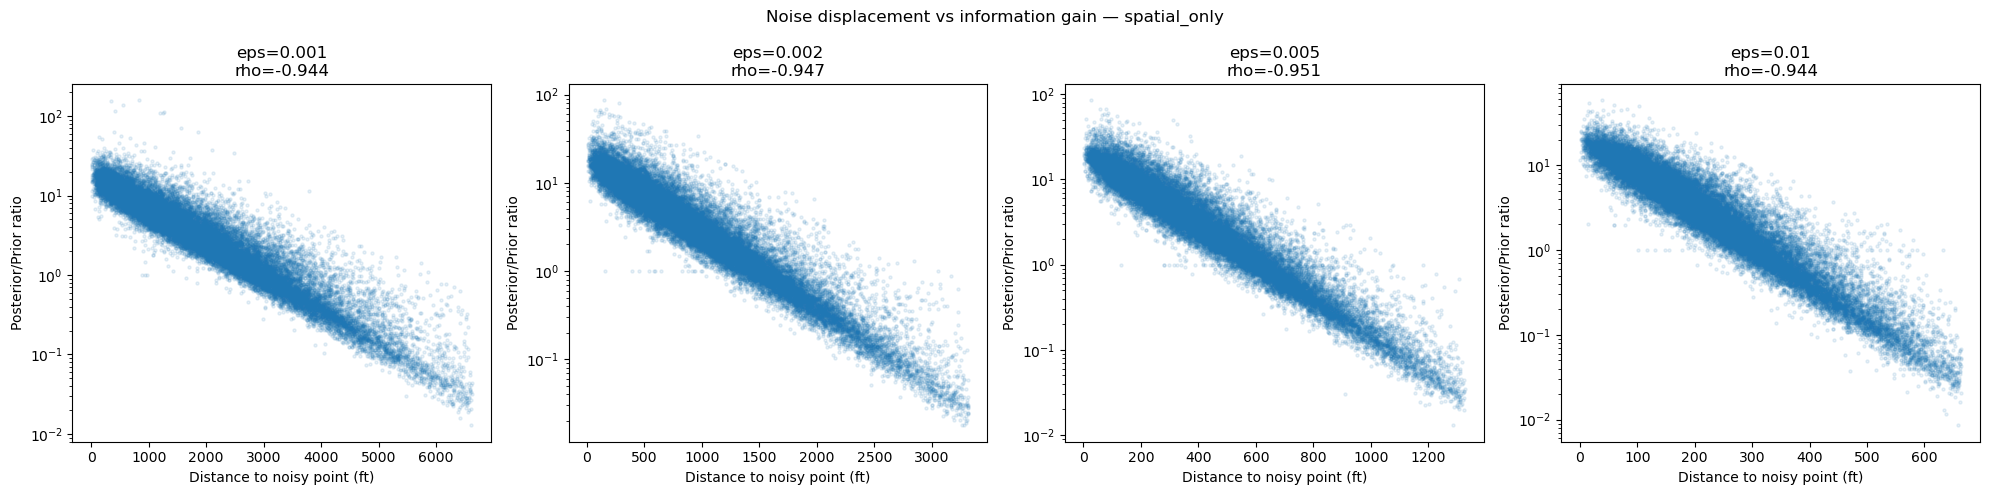

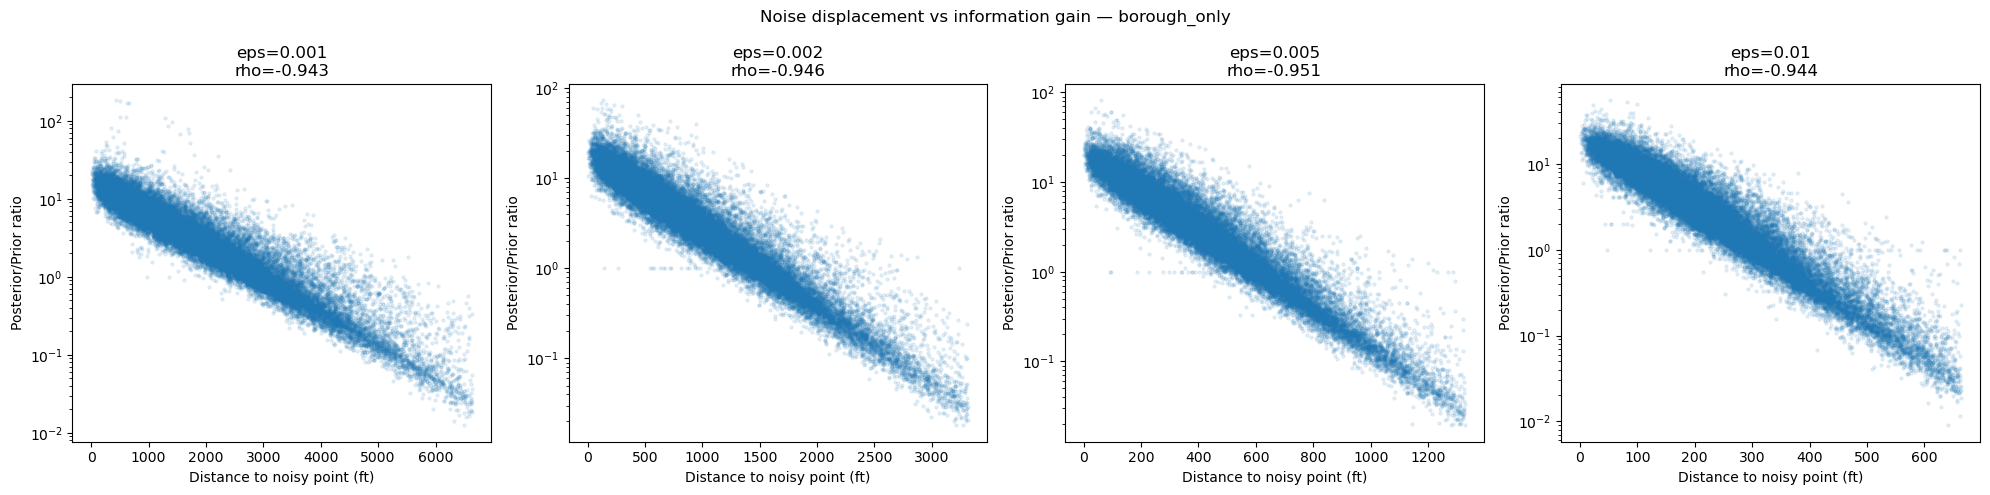

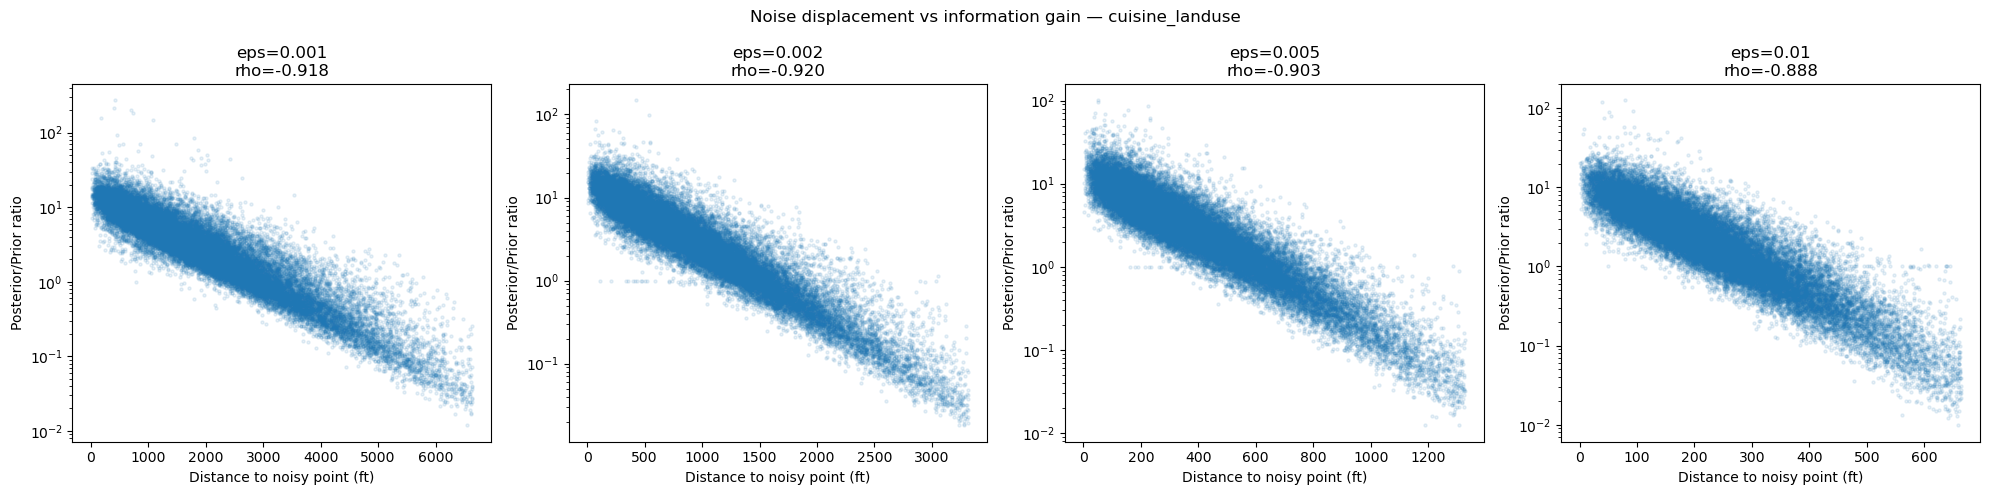

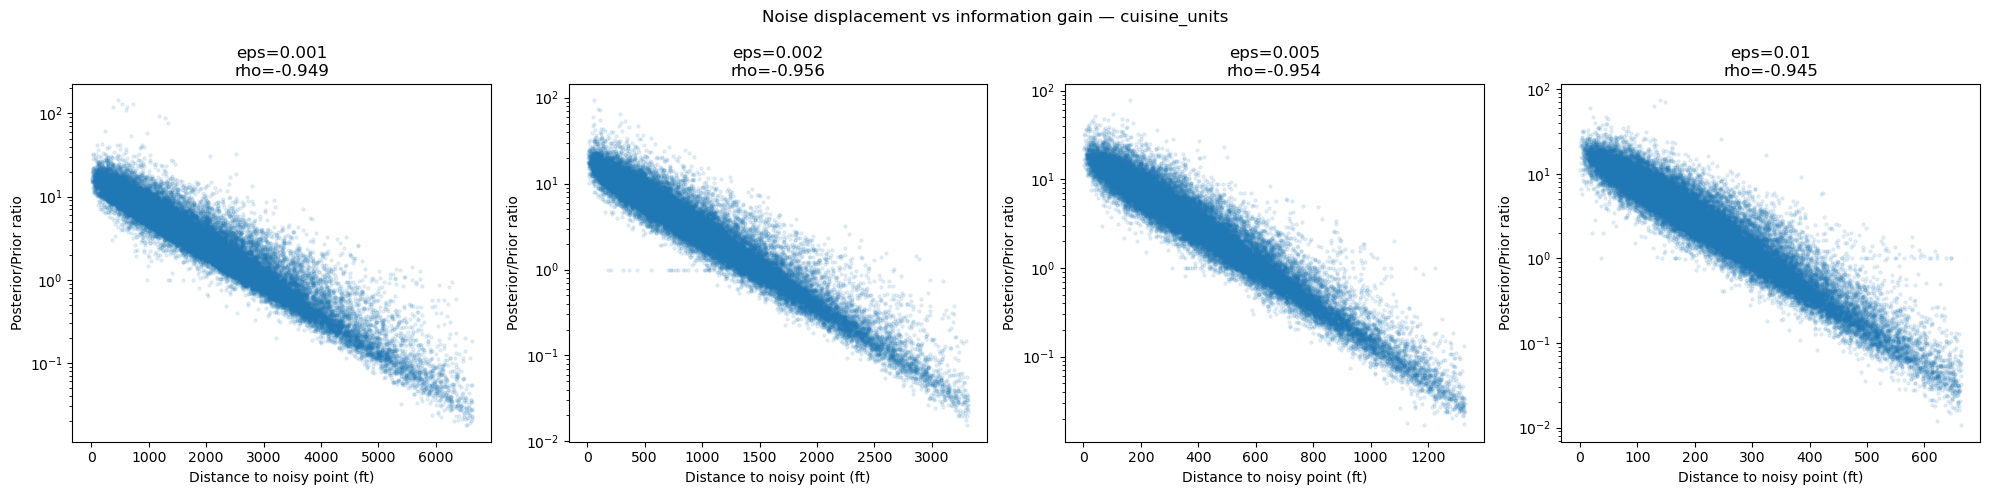

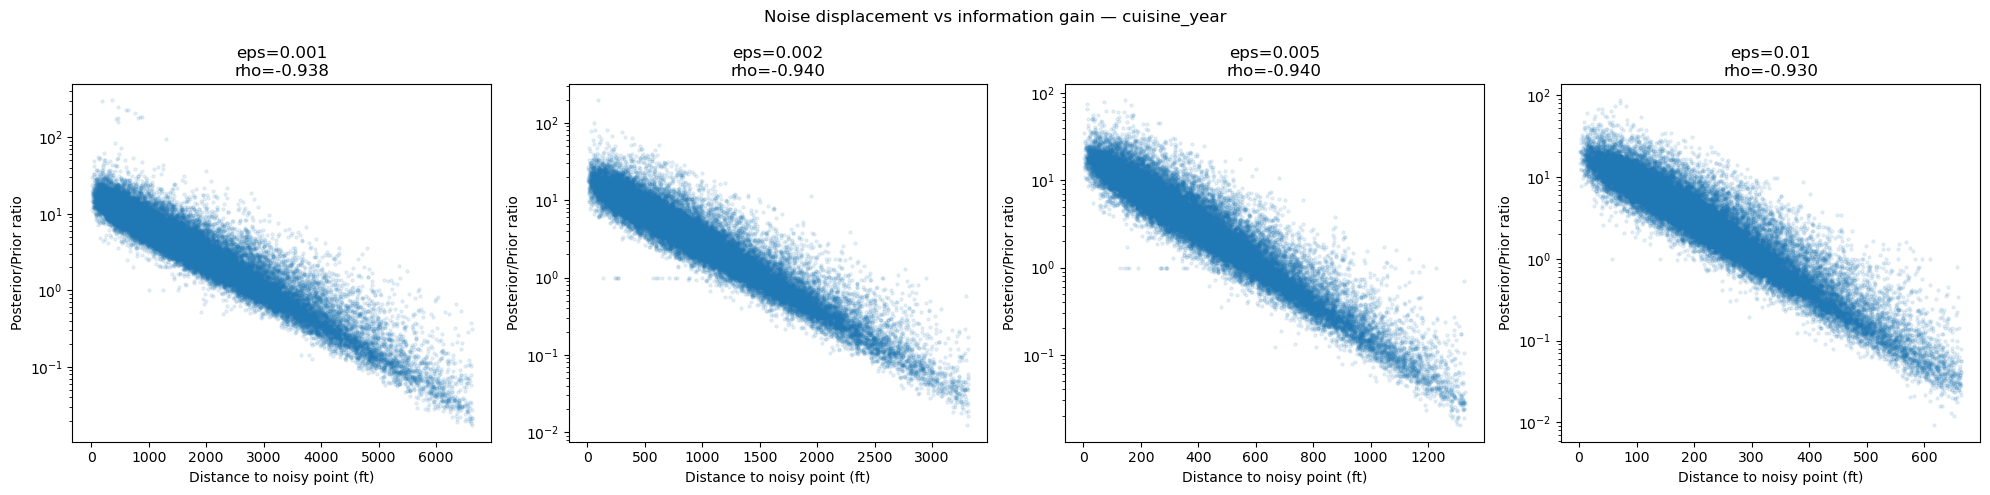

In [29]:
# ── Noise displacement vs information gain — all configs ──

for config_name in configs:
    fig, axes = plt.subplots(1, len(epsilon_vals), figsize=(5*len(epsilon_vals), 5))
    if len(epsilon_vals) == 1: axes = [axes]
    for ax, eps in zip(axes, epsilon_vals):
        df_d = detailed.get((eps, config_name))
        if df_d is None or len(df_d) == 0: continue
        ax.scatter(df_d['dist_to_noisy'], df_d['ratio'], alpha=0.1, s=5)
        rho, p = spearmanr(df_d['dist_to_noisy'], df_d['ratio'])
        ax.set_xlabel('Distance to noisy point (ft)')
        ax.set_ylabel('Posterior/Prior ratio')
        ax.set_title(f'eps={eps}\nrho={rho:.3f}')
        ax.set_yscale('log')
    plt.suptitle(f'Noise displacement vs information gain — {config_name}')
    plt.tight_layout(); plt.show()

## 8. Visualization

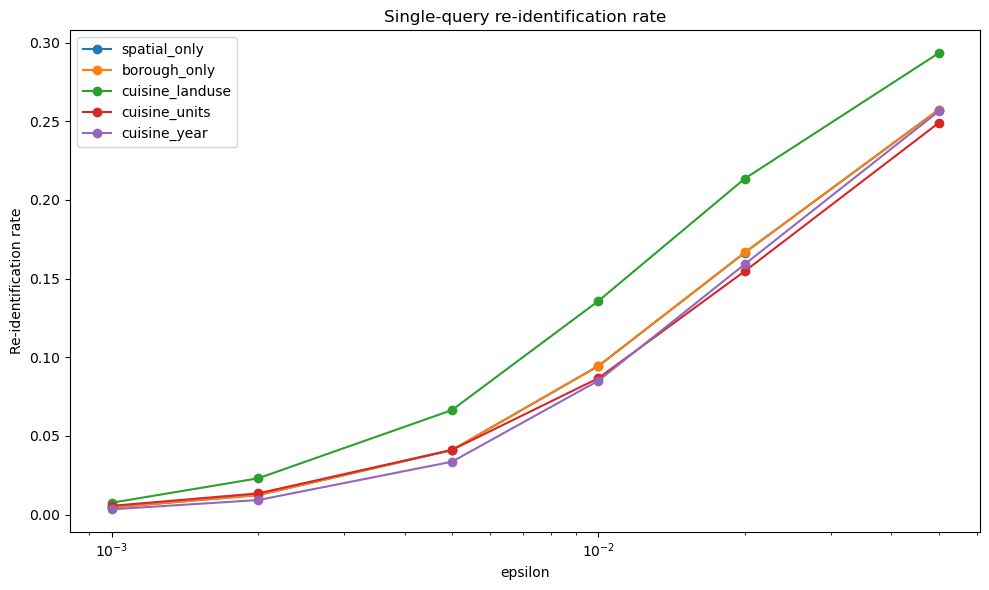

In [46]:
# ── 8a. Single-query re-identification rate vs epsilon ──

fig, ax = plt.subplots(figsize=(10, 6))
for cfg in configs:
    sub = results_df[results_df['config'] == cfg]
    ax.plot(sub['epsilon'], sub['reid_rate'], marker='o', label=cfg)
ax.set_xscale('log')
ax.set_xlabel('epsilon')
ax.set_ylabel('Re-identification rate')
ax.set_title('Single-query re-identification rate')
ax.legend()
plt.tight_layout(); plt.show()

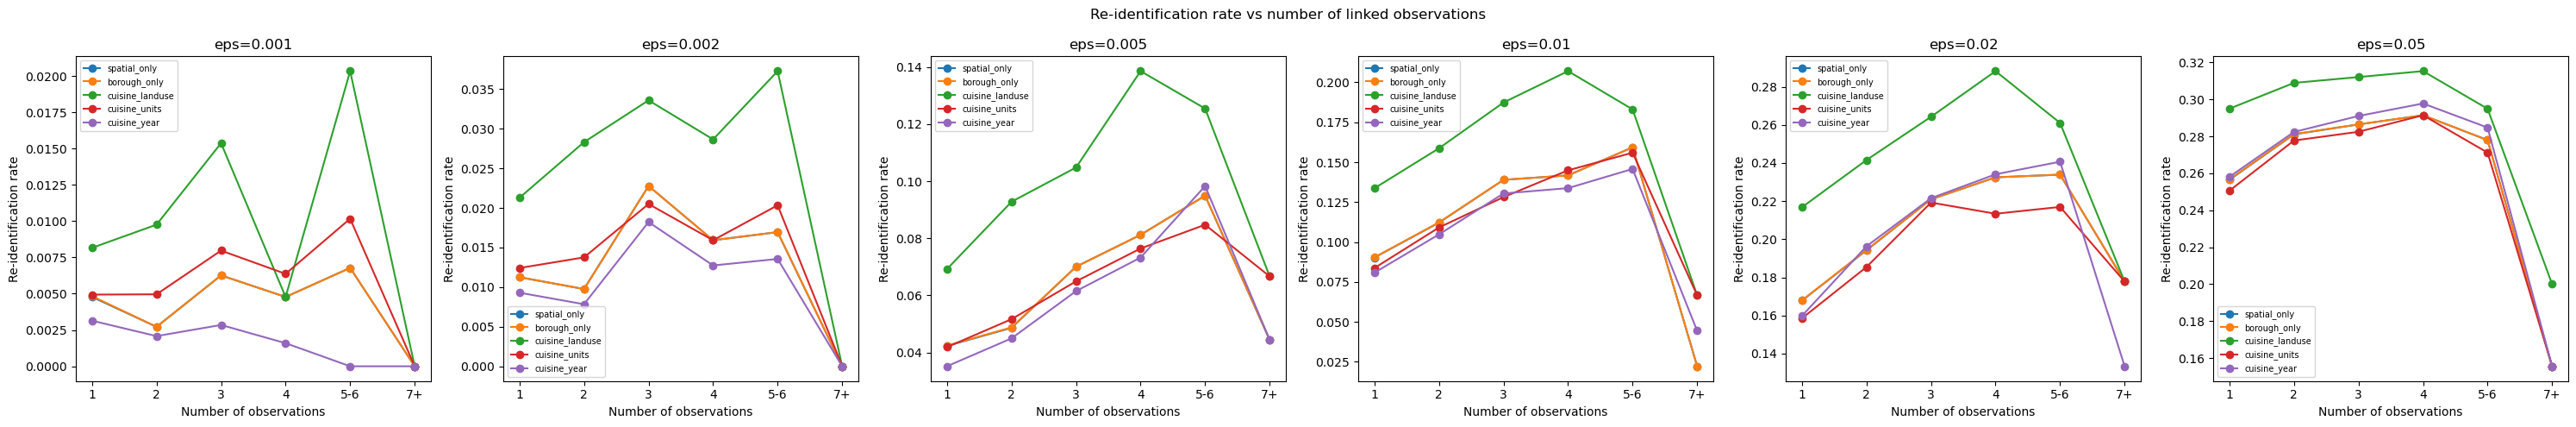


=== Restaurants per bucket ===
epsilon   0.001  0.002  0.005  0.010  0.020  0.050
n_bucket                                          
1         37860  37860  37860  37860  37860  37860
2          6251   6251   6251   6251   6251   6251
3          1756   1756   1756   1756   1756   1756
4           628    628    628    628    628    628
5-6         295    295    295    295    295    295
7+           45     45     45     45     45     45


In [27]:
def bucket_n(n):
    if n == 1: return '1'
    if n == 2: return '2'
    if n == 3: return '3'
    if n == 4: return '4'
    if n <= 6: return '5-6'
    return '7+'

# add single-query results as n=1
single_as_multi = []
for eps in epsilon_vals:
    for config_name in configs:
        reid = results_df[
            (results_df['config'] == config_name) &
            (results_df['epsilon'] == eps)
        ]['reid_rate'].values[0]
        single_as_multi.append({
            'epsilon': eps, 'n_obs': 1, 'config': config_name,
            'reid_rate': reid, 'n_restaurants': len(test)
        })

combined_df = pd.concat([pd.DataFrame(single_as_multi), multi_df], ignore_index=True)
combined_df['n_bucket'] = combined_df['n_obs'].apply(bucket_n)

# weighted average within buckets
binned = (combined_df
    .groupby(['epsilon', 'config', 'n_bucket'])
    .apply(lambda g: pd.Series({
        'reid_rate': np.average(g['reid_rate'], weights=g['n_restaurants']),
        'n_restaurants': g['n_restaurants'].sum()
    }))
    .reset_index()
)

bucket_order = ['1', '2', '3', '4', '5-6', '7+']

fig, axes = plt.subplots(1, len(epsilon_vals), figsize=(5*len(epsilon_vals), 5))
if len(epsilon_vals) == 1: axes = [axes]

for ax, eps in zip(axes, epsilon_vals):
    sub = binned[binned['epsilon'] == eps]
    for cfg in configs:
        cfg_sub = sub[sub['config'] == cfg].copy()
        cfg_sub['n_bucket'] = pd.Categorical(cfg_sub['n_bucket'], categories=bucket_order, ordered=True)
        cfg_sub = cfg_sub.sort_values('n_bucket')
        ax.plot(range(len(cfg_sub)), cfg_sub['reid_rate'].values, marker='o', label=cfg)
    ax.set_xticks(range(len(bucket_order)))
    ax.set_xticklabels(bucket_order)
    ax.set_xlabel('Number of observations')
    ax.set_ylabel('Re-identification rate')
    ax.set_title(f'eps={eps}')
    ax.legend(fontsize=7)

plt.suptitle('Re-identification rate vs number of linked observations')
plt.tight_layout()
plt.show()

# sample sizes
print("\n=== Restaurants per bucket ===")
sizes = binned[binned['config'] == 'spatial_only'][['epsilon', 'n_bucket', 'n_restaurants']]
print(sizes.pivot(index='n_bucket', columns='epsilon', values='n_restaurants').astype(int))

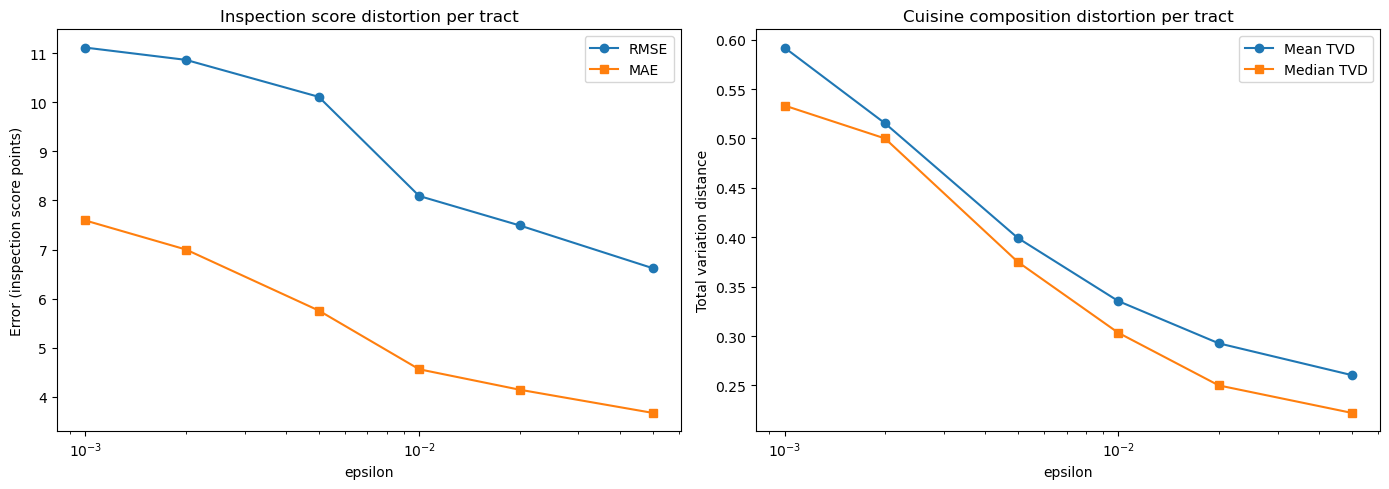

In [28]:
# ── 8c. Utility loss vs epsilon ──

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax = axes[0]
ax.plot(utility_score_df['epsilon'], utility_score_df['rmse'], marker='o', label='RMSE')
ax.plot(utility_score_df['epsilon'], utility_score_df['mae'], marker='s', label='MAE')
ax.set_xscale('log')
ax.set_xlabel('epsilon')
ax.set_ylabel('Error (inspection score points)')
ax.set_title('Inspection score distortion per tract')
ax.legend()

ax = axes[1]
ax.plot(utility_cuisine_df['epsilon'], utility_cuisine_df['tvd_mean'], marker='o', label='Mean TVD')
ax.plot(utility_cuisine_df['epsilon'], utility_cuisine_df['tvd_median'], marker='s', label='Median TVD')
ax.set_xscale('log')
ax.set_xlabel('epsilon')
ax.set_ylabel('Total variation distance')
ax.set_title('Cuisine composition distortion per tract')
ax.legend()

plt.tight_layout(); plt.show()

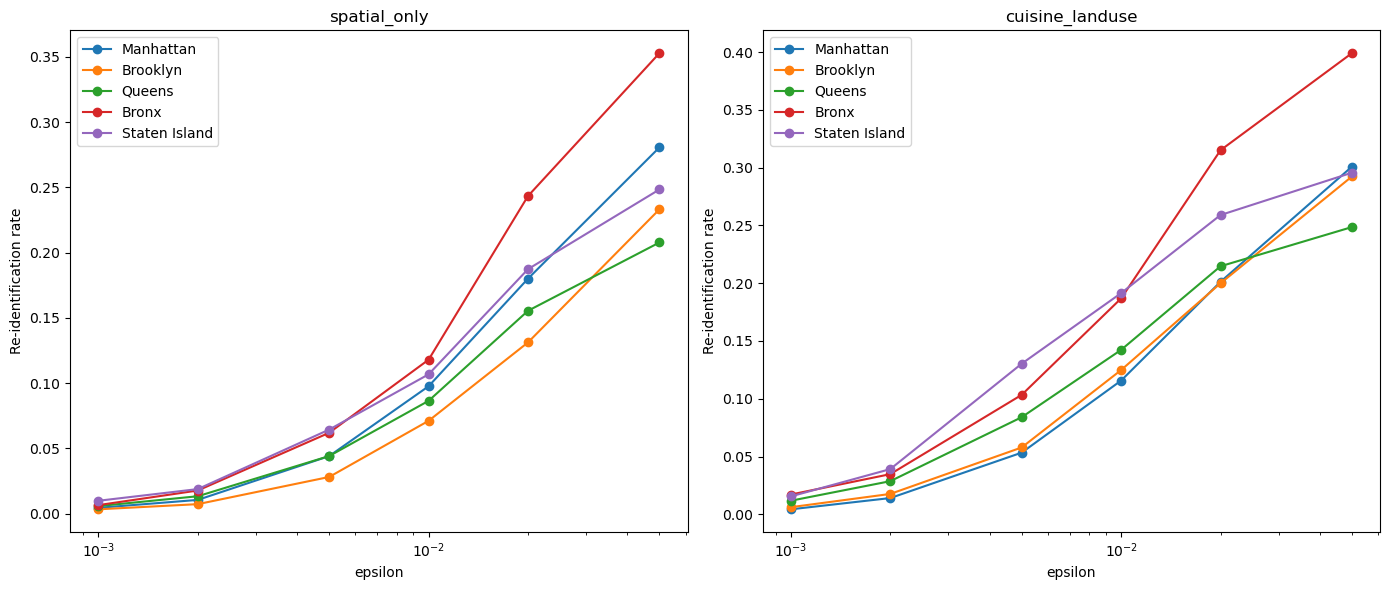

In [29]:
# ── 8d. Borough-stratified re-identification ──

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, cfg in zip(axes, ['spatial_only', 'cuisine_landuse']):
    sub = borough_df[borough_df['config'] == cfg]
    for borough in ['Manhattan', 'Brooklyn', 'Queens', 'Bronx', 'Staten Island']:
        b = sub[sub['borough'] == borough]
        ax.plot(b['epsilon'], b['reid_rate'], marker='o', label=borough)
    ax.set_xscale('log')
    ax.set_xlabel('epsilon')
    ax.set_ylabel('Re-identification rate')
    ax.set_title(cfg)
    ax.legend()
plt.tight_layout(); plt.show()

In [30]:
# ══════════════════════════════════════════════════
# COMBINED SUMMARY
# ══════════════════════════════════════════════════

print('=' * 80)
print('1. SINGLE-QUERY RE-IDENTIFICATION RATE')
print('=' * 80)
print(results_df.pivot(index='epsilon', columns='config', values='reid_rate').round(4))

print('\n' + '=' * 80)
print('2. MULTI-RECORD RE-IDENTIFICATION RATE (spatial_only)')
print('=' * 80)
sub = multi_df[multi_df['config'] == 'spatial_only']
print(sub.pivot(index='n_obs', columns='epsilon', values='reid_rate').round(4))

print('\n' + '=' * 80)
print('3. UTILITY LOSS')
print('=' * 80)
print('Inspection score distortion:')
print(utility_score_df.to_string(index=False))
print('\nCuisine composition distortion:')
print(utility_cuisine_df.to_string(index=False))

print('\n' + '=' * 80)
print('4. POSTERIOR ANALYSIS')
print('=' * 80)
print(f'{"config":20s} {"eps":>8s} {"med P(t|z)":>12s} {"med ratio":>10s} {"P>0.5":>8s} {"bound ok":>10s}')
for eps in epsilon_vals:
    for cfg in configs:
        df_d = detailed.get((eps, cfg))
        if df_d is None or len(df_d) == 0: continue
        print(f'{cfg:20s} {eps:>8.3f} {np.median(df_d["posterior_true"]):>12.4f} '
              f'{np.median(df_d["ratio"]):>10.2f} '
              f'{np.mean(df_d["posterior_true"] > 0.5):>8.4f} '
              f'{df_d["bound_satisfied"].mean()*100:>9.1f}%')

print('\n' + '=' * 80)
print('5. BOROUGH STRATIFICATION')
print('=' * 80)
for cfg in ['spatial_only', 'cuisine_landuse']:
    print(f'\n--- {cfg} ---')
    print(borough_df[borough_df['config']==cfg]
          .pivot(index='epsilon', columns='borough', values='reid_rate').round(4))

1. SINGLE-QUERY RE-IDENTIFICATION RATE
config   borough_only  cuisine_landuse  cuisine_units  cuisine_year  \
epsilon                                                               
0.001          0.0048           0.0082         0.0049        0.0031   
0.002          0.0113           0.0213         0.0124        0.0093   
0.005          0.0424           0.0692         0.0419        0.0352   
0.010          0.0904           0.1337         0.0837        0.0809   
0.020          0.1679           0.2168         0.1585        0.1597   
0.050          0.2567           0.2950         0.2506        0.2581   

config   spatial_only  
epsilon                
0.001          0.0048  
0.002          0.0113  
0.005          0.0423  
0.010          0.0903  
0.020          0.1678  
0.050          0.2565  

2. MULTI-RECORD RE-IDENTIFICATION RATE (spatial_only)
epsilon   0.001   0.002   0.005   0.010   0.020   0.050
n_obs                                                  
2        0.0027  0.0098  0.0486  

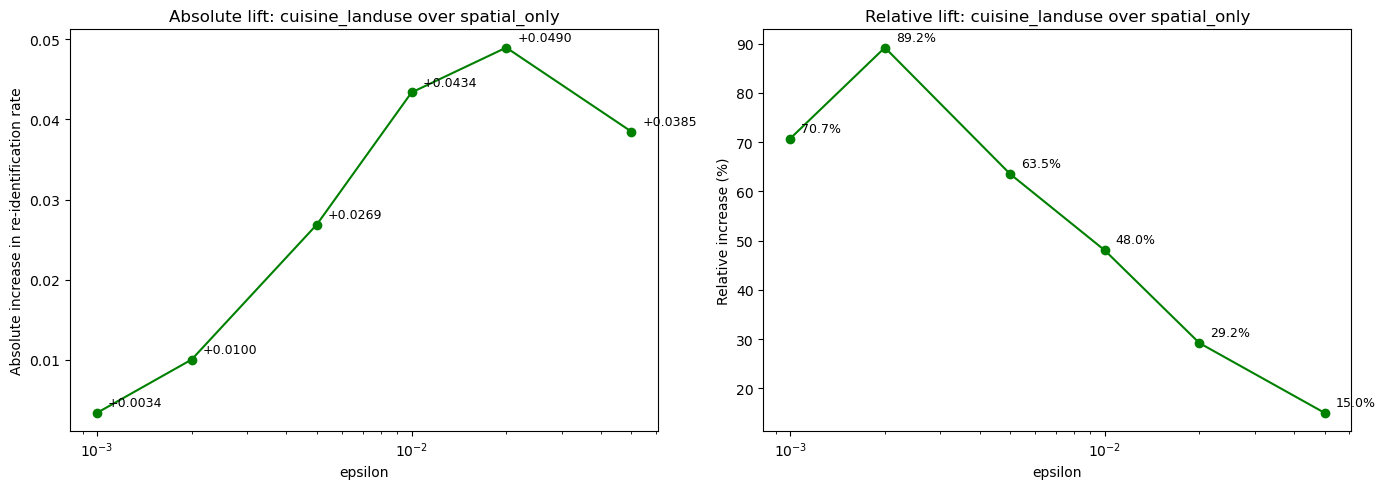

 epsilon    spatial   cuisine_lu   abs lift   rel lift
-------------------------------------------------------
   0.001     0.0048       0.0082     0.0034      70.7%
   0.002     0.0113       0.0213     0.0100      89.2%
   0.005     0.0423       0.0692     0.0269      63.5%
   0.010     0.0903       0.1337     0.0434      48.0%
   0.020     0.1678       0.2168     0.0490      29.2%
   0.050     0.2565       0.2950     0.0385      15.0%


In [31]:
# compute lift: best prior (cuisine_landuse) vs spatial_only at each epsilon
spatial = results_df[results_df['config'] == 'spatial_only'].sort_values('epsilon')
cuisine = results_df[results_df['config'] == 'cuisine_landuse'].sort_values('epsilon')

eps_vals = spatial['epsilon'].values
spatial_rates = spatial['reid_rate'].values
cuisine_rates = cuisine['reid_rate'].values

absolute_lift = cuisine_rates - spatial_rates
relative_lift = absolute_lift / spatial_rates

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax = axes[0]
ax.plot(eps_vals, absolute_lift, marker='o', color='green')
ax.set_xscale('log')
ax.set_xlabel('epsilon')
ax.set_ylabel('Absolute increase in re-identification rate')
ax.set_title('Absolute lift: cuisine_landuse over spatial_only')
for i, eps in enumerate(eps_vals):
    ax.annotate(f'+{absolute_lift[i]:.4f}', (eps, absolute_lift[i]),
                textcoords='offset points', xytext=(8, 5), fontsize=9)

ax = axes[1]
ax.plot(eps_vals, relative_lift * 100, marker='o', color='green')
ax.set_xscale('log')
ax.set_xlabel('epsilon')
ax.set_ylabel('Relative increase (%)')
ax.set_title('Relative lift: cuisine_landuse over spatial_only')
for i, eps in enumerate(eps_vals):
    ax.annotate(f'{relative_lift[i]*100:.1f}%', (eps, relative_lift[i]*100),
                textcoords='offset points', xytext=(8, 5), fontsize=9)

plt.tight_layout()
plt.show()

# print table
print(f"{'epsilon':>8s} {'spatial':>10s} {'cuisine_lu':>12s} {'abs lift':>10s} {'rel lift':>10s}")
print("-" * 55)
for i in range(len(eps_vals)):
    print(f"{eps_vals[i]:>8.3f} {spatial_rates[i]:>10.4f} {cuisine_rates[i]:>12.4f} "
          f"{absolute_lift[i]:>10.4f} {relative_lift[i]*100:>9.1f}%")

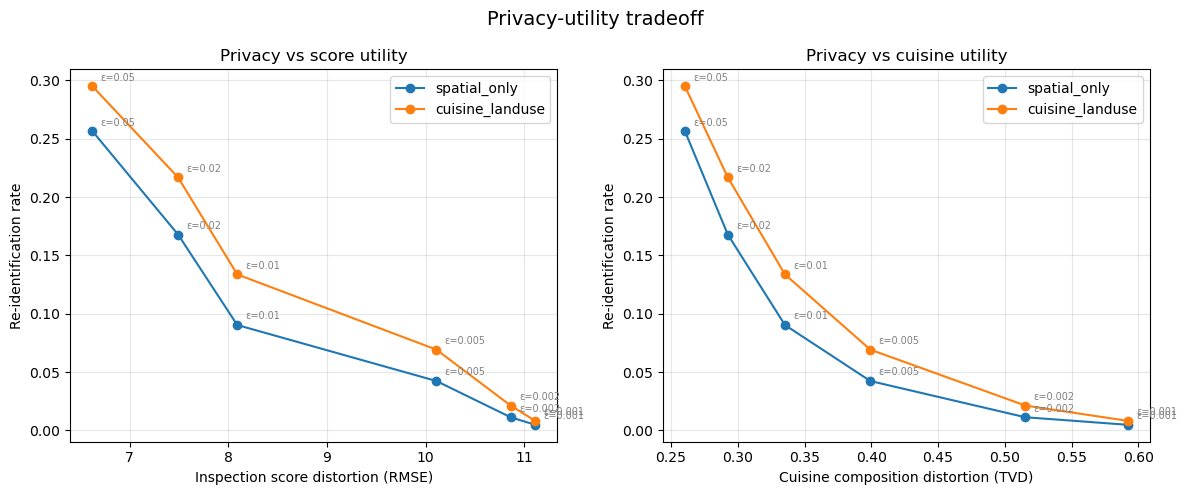

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# left: re-identification vs inspection score RMSE
ax = axes[0]
for cfg in ['spatial_only', 'cuisine_landuse']:
    sub = results_df[results_df['config'] == cfg].sort_values('epsilon')
    reid = sub['reid_rate'].values
    rmse = utility_score_df.sort_values('epsilon')['rmse'].values
    
    # align lengths (utility may have fewer epsilon values)
    n = min(len(reid), len(rmse))
    eps = sub['epsilon'].values[:n]
    
    ax.plot(rmse[:n], reid[:n], marker='o', label=cfg)
    for i in range(n):
        ax.annotate(f'ε={eps[i]}', (rmse[i], reid[i]),
                   textcoords='offset points', xytext=(6, 4), fontsize=7, color='gray')

ax.set_xlabel('Inspection score distortion (RMSE)')
ax.set_ylabel('Re-identification rate')
ax.set_title('Privacy vs score utility')
ax.legend()
ax.grid(True, alpha=0.3)

# right: re-identification vs cuisine TVD
ax = axes[1]
for cfg in ['spatial_only', 'cuisine_landuse']:
    sub = results_df[results_df['config'] == cfg].sort_values('epsilon')
    reid = sub['reid_rate'].values
    tvd = utility_cuisine_df.sort_values('epsilon')['tvd_mean'].values
    
    n = min(len(reid), len(tvd))
    eps = sub['epsilon'].values[:n]
    
    ax.plot(tvd[:n], reid[:n], marker='o', label=cfg)
    for i in range(n):
        ax.annotate(f'ε={eps[i]}', (tvd[i], reid[i]),
                   textcoords='offset points', xytext=(6, 4), fontsize=7, color='gray')

ax.set_xlabel('Cuisine composition distortion (TVD)')
ax.set_ylabel('Re-identification rate')
ax.set_title('Privacy vs cuisine utility')
ax.legend()
ax.grid(True, alpha=0.3)

plt.suptitle('Privacy-utility tradeoff', fontsize=14)
plt.tight_layout()
plt.show()

## 9. Export results

Writes every number the paper and figures use to `results/`, from this single run. Then run `python scripts/make_figures.py results paper`.

In [ ]:
# ── Export all results from THIS run (paper + figures read only these files) ──
from pathlib import Path
from datetime import date

OUT = Path('results'); OUT.mkdir(exist_ok=True)

results_df[['epsilon', 'config', 'reid_rate']].to_csv(OUT / 'single_query.csv', index=False)
multi_df[['epsilon', 'n_obs', 'config', 'reid_rate', 'n_restaurants']].to_csv(OUT / 'multi_record.csv', index=False)
utility_score_df.to_csv(OUT / 'utility_score.csv', index=False)
utility_cuisine_df.to_csv(OUT / 'utility_cuisine.csv', index=False)
borough_df[['config', 'epsilon', 'borough', 'reid_rate']].to_csv(OUT / 'borough.csv', index=False)

pd.DataFrame([{'borough': b, 'mean_candidates': round(np.mean(v)), 'median_candidates': round(np.median(v))}
              for b, v in borough_cands.items()]).to_csv(OUT / 'candidate_density.csv', index=False)

pd.DataFrame({'epsilon': eps_vals, 'spatial_only': spatial_rates, 'cuisine_landuse': cuisine_rates,
              'abs_lift': absolute_lift, 'rel_lift_pct': relative_lift * 100}
             ).to_csv(OUT / 'prior_lift.csv', index=False)

# posterior summary, plus the quantities the paper cites but the old run never printed
rows = []
for (eps, cfg), d in detailed.items():
    if len(d) == 0:
        continue
    rho, p = spearmanr(d['dist_to_noisy'], d['ratio'])
    rows.append({
        'config': cfg, 'epsilon': eps,
        'median_posterior_true': d['posterior_true'].median(),
        'median_ratio': d['ratio'].median(), 'p99_ratio': d['ratio'].quantile(0.99), 'max_ratio': d['ratio'].max(),
        'share_posterior_gt_0_5': (d['posterior_true'] > 0.5).mean(),
        'bound_satisfied_pct': d['bound_satisfied'].mean() * 100,
        'median_bound': d['tight_bound'].median(), 'min_bound': d['tight_bound'].min(),
        'median_bound_over_ratio': (d['tight_bound'] / d['ratio']).median(),
        'spearman_rho_disp_ratio': rho, 'spearman_p': p,
    })
pd.DataFrame(rows).to_csv(OUT / 'posterior_summary.csv', index=False)

# prior strength (max conditional probability per cuisine, averaged)
pd.DataFrame([{'prior': k, 'avg_max_prob': t.max(axis=1).mean()} for k, t in prior_tables.items()]
             ).to_csv(OUT / 'prior_strength.csv', index=False)

pd.Series({
    'run_date': date.today().isoformat(),
    'pluto_lots': len(ref_df),
    'train_visits': len(train_visits), 'train_restaurants': train_visits['camis'].nunique(),
    'train_joined_to_pluto': len(train_merged),
    'test_visits': len(test), 'test_restaurants': test['camis'].nunique(),
    'test_restaurants_2plus': int((multi_counts >= 2).sum()),
    'test_restaurants_3plus': int((multi_counts >= 3).sum()),
}).rename_axis('quantity').rename('value').to_csv(OUT / 'data_summary.csv')

print('Wrote:', sorted(f.name for f in OUT.glob('*.csv')))
